# Between-system contrasts can inflate remote sensing accuracy for soil carbon: a call for within-field validation

Analysis notebook for Oliveira et al. (submitted to *Precision Agriculture*). Data: `../data` (samples, points and covariates, described in `../data/dictionary.csv`). Outputs (tables and figures, PNG 600 dpi and vector PDF) are written to `../results`.

Codes in the code → codes in the article: `MN` → NF (native forest), `ILP8` → ICL (integrated crop–livestock system), `PM` → MP (managed pasture); `COT` → SOC, `COP` → POC, `COM` → MAOC (g kg⁻¹); layers in cm (0-10 cm = 0–100 mm). Covariate prefixes: `DR_` UAV, `PL_` PlanetScope, `S2_` Sentinel-2 single date (dry season 2024), `S2c_` Sentinel-2 wet-season bare-soil composite (2025), `S2s_` Sentinel-2 time series 2019–2024.

Run the cells in order. Random seeds are fixed.

In [1]:
# %pip install -r ../requirements.txt

In [2]:
import os, importlib, warnings; warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
%matplotlib inline
import pandas as pd, numpy as np
import soc_analysis as R; importlib.reload(R)
R.estilo_publicacao()
DATA = '../data'        # samples.csv, points.csv, covariates.csv, s2_series_grid_10m.csv
OUT = '../results'      # tables and figures
os.makedirs(OUT, exist_ok=True)
R.N_ARVORES = 300       # trees in the Random Forest

## 1. Data (three layers)
SOC, POC and MAOC (g kg⁻¹) of the three layers, dry season. POC values in the 0–10 cm layer with a robust z-score |z| > 3.5 (median absolute deviation, within system) are flagged for the sensitivity analysis (ICL points 6–9).

In [3]:
d = R.carregar(DATA)
display(d.head())

180 amostras do período seco (corrected); COP marcado (sensibilidade): [['MN', 1, '20-30cm', 0.059], ['MN', 7, '20-30cm', 0.177], ['MN', 8, '20-30cm', 0.624], ['ILP8', 6, '0-10cm', 2.069], ['ILP8', 7, '0-10cm', 2.186], ['ILP8', 8, '0-10cm', 2.098], ['ILP8', 9, '0-10cm', 2.046]]


,Tratamento,Amostra,Camada,COT,COP,COM,lon,lat,E,N,...,S2s_NDVI_chuva,S2s_NDVI_dp,S2s_NDVI_seca,S2s_freq_solo_exposto,TPI150,decliv,elev,SG_clay,SG_sand,flag_COP
0,MN,1,0-10cm,20.104,0.266,19.838,-42.970426,-3.701481,725419.88,9590611.57,...,0.761562,0.125036,0.673143,0.014572,2.925201,1,104.439575,36.666667,37.766667,False
1,MN,1,10-20cm,16.688,0.205,16.483,-42.970426,-3.701481,725419.88,9590611.57,...,0.761562,0.125036,0.673143,0.014572,2.925201,1,104.439575,36.666667,37.766667,False
2,MN,1,20-30cm,12.123,0.059,12.064,-42.970426,-3.701481,725419.88,9590611.57,...,0.761562,0.125036,0.673143,0.014572,2.925201,1,104.439575,36.666667,37.766667,True
3,MN,2,0-10cm,13.427,0.266,13.161,-42.968635,-3.701477,725618.89,9590611.57,...,0.640035,0.123382,0.505339,0.012806,0.863106,1,103.486534,37.433333,37.433333,False
4,MN,2,10-20cm,13.127,0.181,12.946,-42.968635,-3.701477,725618.89,9590611.57,...,0.640035,0.123382,0.505339,0.012806,0.863106,1,103.486534,37.433333,37.433333,False


## 2. Covariates
The covariates are provided in `../data/covariates.csv`: UAV and PlanetScope indices, Sentinel-2 bands and indices (single date, wet-season composite and 2019–2024 time series), Copernicus GLO-30 terrain (elevation, slope, TPI) and SoilGrids 2.0 texture. They were extracted with Google Earth Engine by `soc_analysis.coletar_covariaveis` (requires an Earth Engine account; not needed to reproduce the results).

In [4]:
w = R.tabela_ponto(d)
print(w.shape)

(60, 66)


## 3. SOC, POC and MAOC by system (three layers)
### 3.1 Statistical tests
Linear model on the log of the variable, Kruskal–Wallis test and pairwise Mann–Whitney tests with Holm correction.

In [5]:
comp = R.comparar_sistemas(d)
for v in comp:
    print(f'\n######## {v}')
    display(comp[v]['descr'].unstack('Tratamento'))
    display(comp[v]['pares'].round(4))


=== COT (log) ===
                                            Coef. Std.Err.       z  P>|z|  \
Intercept                                  2.621    0.048  54.552  0.000   
C(Tratamento)[T.MN]                       -0.054    0.068  -0.792  0.429   
C(Tratamento)[T.PM]                       -0.022    0.068  -0.327  0.744   
C(Camada)[T.10-20cm]                      -0.190    0.037  -5.086  0.000   
C(Camada)[T.20-30cm]                      -0.297    0.037  -7.961  0.000   
C(Tratamento)[T.MN]:C(Camada)[T.10-20cm]   0.242    0.053   4.586  0.000   
C(Tratamento)[T.PM]:C(Camada)[T.10-20cm]  -0.007    0.053  -0.134  0.894   
C(Tratamento)[T.MN]:C(Camada)[T.20-30cm]   0.001    0.053   0.011  0.991   
C(Tratamento)[T.PM]:C(Camada)[T.20-30cm]  -0.068    0.053  -1.290  0.197   
Group Var                                  0.032    0.072                  

                                          [0.025  0.975]  
Intercept                                  2.527   2.715  
C(Tratamento)[T.MN]      


=== COM (log) ===
                                            Coef. Std.Err.       z  P>|z|  \
Intercept                                  2.551    0.049  52.041  0.000   
C(Tratamento)[T.MN]                        0.002    0.069   0.029  0.977   
C(Tratamento)[T.PM]                        0.026    0.069   0.378  0.706   
C(Camada)[T.10-20cm]                      -0.152    0.039  -3.943  0.000   
C(Camada)[T.20-30cm]                      -0.266    0.039  -6.905  0.000   
C(Tratamento)[T.MN]:C(Camada)[T.10-20cm]   0.204    0.055   3.731  0.000   
C(Tratamento)[T.PM]:C(Camada)[T.10-20cm]  -0.037    0.055  -0.679  0.497   
C(Tratamento)[T.MN]:C(Camada)[T.20-30cm]  -0.055    0.055  -1.007  0.314   
C(Tratamento)[T.PM]:C(Camada)[T.20-30cm]  -0.097    0.055  -1.781  0.075   
Group Var                                  0.033    0.072                  

                                          [0.025  0.975]  
Intercept                                  2.455   2.648  
C(Tratamento)[T.MN]      

mean                    sem               count        
Tratamento    ILP8      MN      PM   ILP8     MN     PM  ILP8  MN  PM
Camada                                                               
0-10cm      14.006  13.488  13.935  0.595  0.833  0.878    20  20  20
10-20cm     11.565  14.008  11.178  0.480  0.629  0.427    20  20  20
20-30cm     10.419   9.932   9.489  0.464  0.520  0.422    20  20  20

,Camada,par,p,p_Holm
0,0-10cm,ILP8 x MN,0.3369,1.0000
1,0-10cm,ILP8 x PM,0.4249,1.0000
2,0-10cm,MN x PM,0.7150,1.0000
3,10-20cm,ILP8 x MN,0.0077,0.0154
4,10-20cm,ILP8 x PM,0.3942,0.3942
5,10-20cm,MN x PM,0.0013,0.0040
6,20-30cm,ILP8 x MN,0.4249,0.8498
7,20-30cm,ILP8 x PM,0.1017,0.3052
8,20-30cm,MN x PM,0.6359,0.8498



######## COP


mean                  sem               count        
Tratamento   ILP8     MN     PM   ILP8     MN     PM  ILP8  MN  PM
Camada                                                            
0-10cm      0.956  0.178  0.283  0.133  0.018  0.033    20  20  20
10-20cm     0.350  0.195  0.144  0.027  0.012  0.013    20  20  20
20-30cm     0.372  0.353  0.173  0.030  0.025  0.015    20  20  20

,Camada,par,p,p_Holm
0,0-10cm,ILP8 x MN,0.0000,0.0000
1,0-10cm,ILP8 x PM,0.0000,0.0000
2,0-10cm,MN x PM,0.0337,0.0337
3,10-20cm,ILP8 x MN,0.0002,0.0005
4,10-20cm,ILP8 x PM,0.0000,0.0000
5,10-20cm,MN x PM,0.0293,0.0293
6,20-30cm,ILP8 x MN,0.3941,0.3941
7,20-30cm,ILP8 x PM,0.0000,0.0001
8,20-30cm,MN x PM,0.0000,0.0000



######## COM


mean                    sem               count        
Tratamento    ILP8      MN      PM   ILP8     MN     PM  ILP8  MN  PM
Camada                                                               
0-10cm      13.050  13.310  13.653  0.535  0.828  0.871    20  20  20
10-20cm     11.214  13.813  11.034  0.480  0.629  0.430    20  20  20
20-30cm     10.048   9.579   9.316  0.474  0.523  0.427    20  20  20

,Camada,par,p,p_Holm
0,0-10cm,ILP8 x MN,0.7764,1.0000
1,0-10cm,ILP8 x PM,0.7764,1.0000
2,0-10cm,MN x PM,0.7764,1.0000
3,10-20cm,ILP8 x MN,0.0051,0.0102
4,10-20cm,ILP8 x PM,0.7150,0.7150
5,10-20cm,MN x PM,0.0013,0.0040
6,20-30cm,ILP8 x MN,0.4407,0.8815
7,20-30cm,ILP8 x PM,0.1988,0.5965
8,20-30cm,MN x PM,0.8604,0.8815


### 3.2 Figure

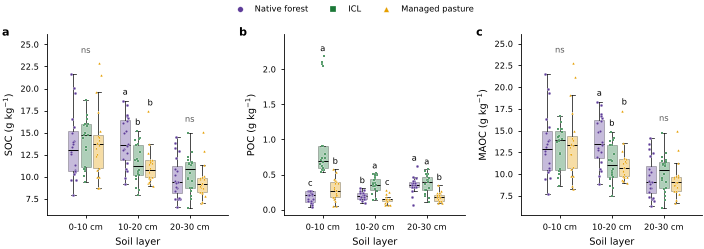

In [6]:
fig = R.fig_carbono_camadas(d, comp, OUT); plt.show()

### 3.3 Multivariate analysis (PCA and PERMANOVA)
0–10 cm layer: POC, MAOC, UAV and PlanetScope indices (NDVI, NDRE, NDWI) and the Sentinel-2 time series, standardised. PERMANOVA tests whether the systems separate.

PCA com 12 variáveis e 60 pontos | PC1 53.1%, PC2 26.9% | PERMANOVA: pseudo-F = 67.9, R² = 0.70, p = 0.0001


,PC1,PC2
COP_0-10,0.14,-0.79
COM_0-10,0.03,0.05
DR_NDVI,-0.78,-0.57
DR_NDRE,-0.59,-0.77
DR_NDWI,0.52,0.82
PL_NDVI,0.53,0.49
PL_NDRE,-0.89,0.38
PL_NDWI,0.90,-0.35
S2s_BSI_seca,0.97,-0.04
S2s_NDVI_chuva,-0.77,0.55


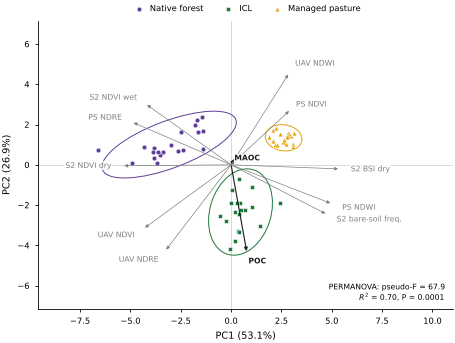

In [7]:
pca = R.pca_sistemas(w)
display(pca['loadings'].round(2))
R.fig_pca(pca, OUT); plt.show()

## 4. Correlation with all points × within each system
If r drops to near zero within the systems, the covariate only recognises the system.

In [8]:
alvos = ['COT_0-10', 'COP_0-10', 'COM_0-10']
covs = [c for c in w.columns if c.startswith(('DR_','PL_','S2_','S2s_','SG_','MB_')) or c in ['elev','decliv','TPI150']]
t = R.correlacao_decomposta(w, alvos, covs)
t.to_csv(os.path.join(OUT, 'correlacao_entre_dentro.csv'), index=False)

### 4.1 SOC (0–10 cm)

,alvo,cov,r_total,p_total,r_dentro,p_dentro,n,p_dentro_FDR,p_total_FDR
11,COT_0-10,S2_B5,-0.040,0.761,-0.233,0.073,60,0.454,0.994
31,COT_0-10,SG_clay,-0.118,0.368,-0.224,0.086,60,0.457,0.994
21,COT_0-10,S2_NDWI,-0.045,0.732,-0.147,0.261,60,0.797,0.994
7,COT_0-10,S2_B12,-0.003,0.984,-0.145,0.268,60,0.797,0.994
9,COT_0-10,S2_B3,-0.023,0.860,-0.145,0.268,60,0.797,0.994
23,COT_0-10,S2s_BSI_seca,-0.013,0.924,-0.145,0.270,60,0.797,0.994
12,COT_0-10,S2_B6,-0.034,0.799,-0.141,0.282,60,0.797,0.994
16,COT_0-10,S2_BSI,-0.004,0.976,-0.130,0.322,60,0.802,0.994
8,COT_0-10,S2_B2,-0.030,0.818,-0.122,0.352,60,0.802,0.994
10,COT_0-10,S2_B4,-0.006,0.961,-0.114,0.386,60,0.802,0.994


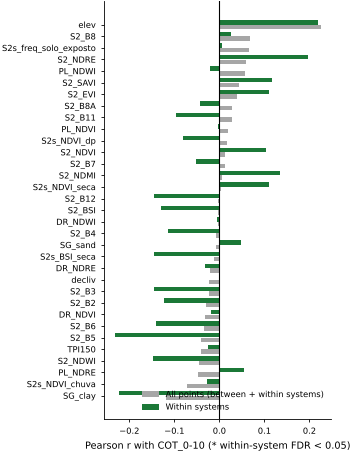

In [9]:
display(t[t.alvo=='COT_0-10'].round(3).sort_values('r_dentro'))
R.fig_entre_dentro(t, OUT, 'COT_0-10'); plt.show()

### 4.2 MAOC (0–10 cm)

,alvo,cov,r_total,p_total,r_dentro,p_dentro,n,p_dentro_FDR,p_total_FDR
77,COM_0-10,S2_B5,-0.055,0.676,-0.211,0.106,60,0.500,0.994
97,COM_0-10,SG_clay,-0.179,0.172,-0.200,0.126,60,0.530,0.853
78,COM_0-10,S2_B6,-0.100,0.446,-0.149,0.254,60,0.797,0.994
89,COM_0-10,S2s_BSI_seca,-0.033,0.802,-0.131,0.318,60,0.802,0.994
87,COM_0-10,S2_NDWI,-0.044,0.739,-0.122,0.354,60,0.802,0.994
75,COM_0-10,S2_B3,-0.040,0.763,-0.120,0.360,60,0.802,0.994
91,COM_0-10,S2s_NDVI_dp,-0.086,0.512,-0.116,0.376,60,0.802,0.994
73,COM_0-10,S2_B12,-0.009,0.948,-0.112,0.394,60,0.802,0.994
82,COM_0-10,S2_BSI,-0.013,0.920,-0.112,0.396,60,0.802,0.994
74,COM_0-10,S2_B2,-0.027,0.835,-0.090,0.493,60,0.843,0.994


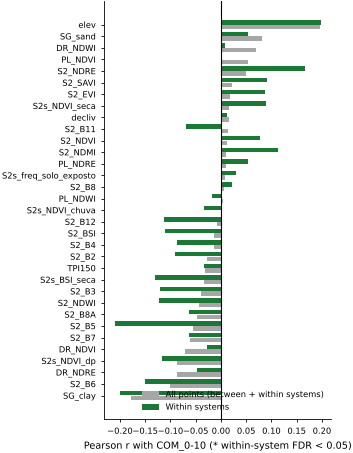

In [10]:
display(t[t.alvo=='COM_0-10'].round(3).sort_values('r_dentro'))
R.fig_entre_dentro(t, OUT, 'COM_0-10'); plt.show()

### 4.3 POC (0–10 cm)

,alvo,cov,r_total,p_total,r_dentro,p_dentro,n,p_dentro_FDR,p_total_FDR
40,COP_0-10,S2_B12,0.040,0.761,-0.350,0.006,60,0.343,0.994
41,COP_0-10,S2_B2,-0.025,0.851,-0.332,0.010,60,0.343,0.994
43,COP_0-10,S2_B4,0.048,0.713,-0.287,0.026,60,0.343,0.994
39,COP_0-10,S2_B11,0.108,0.411,-0.285,0.027,60,0.343,0.994
64,COP_0-10,SG_clay,0.388,0.002,-0.282,0.029,60,0.343,0.018
54,COP_0-10,S2_NDWI,-0.015,0.909,-0.278,0.031,60,0.343,0.994
42,COP_0-10,S2_B3,0.108,0.412,-0.271,0.036,60,0.343,0.994
44,COP_0-10,S2_B5,0.095,0.468,-0.266,0.040,60,0.343,0.994
60,COP_0-10,S2s_freq_solo_exposto,0.407,0.001,-0.222,0.088,60,0.457,0.012
49,COP_0-10,S2_BSI,0.063,0.633,-0.206,0.114,60,0.513,0.994


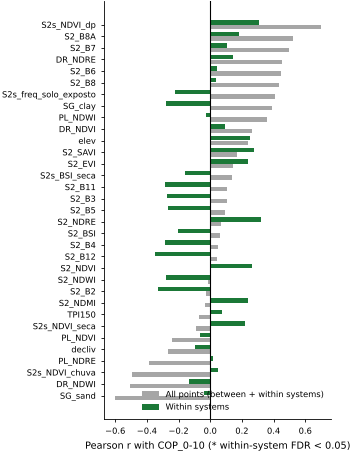

In [11]:
display(t[t.alvo=='COP_0-10'].round(3).sort_values('r_dentro'))
R.fig_entre_dentro(t, OUT, 'COP_0-10'); plt.show()

## 5. Models (RF and PLSR, nested leave-one-out cross-validation)
Each covariate set is compared with **System only** (`Só o sistema`). If R²cv does not exceed it, the imagery recognises the land use but not the carbon within the field. Each block shows the table (R² with 95% CI, R² within systems, RMSE, MAPE), the R² plot and observed × predicted values.

In [12]:
res, preds = {}, {}
def bloco(alvo, dados, rotulo=None):
    rot = rotulo or alvo
    r, p = R.avaliar(dados, alvo, R.conjuntos_padrao(dados)); r['alvo'] = rot
    res[rot], preds[rot] = r, p
    display(r.round(3))
    R.fig_r2(r, OUT, rot); plt.show()
    R.fig_obs_pred(p, alvo, OUT, nome=f'Fig_obs_pred_{rot}'); plt.show()

### 5.1 SOC

,alvo,conjunto,modelo,n,p,R2_cv,R2_IC95_inf,R2_IC95_sup,R2_dentro,RMSE_cv,MAPE_cv,vies
0,COT_0-10,Só o sistema,RF,60,3,-0.101,-0.205,-0.065,-0.106,3.568,21.395,0.006
1,COT_0-10,Só o sistema,PLSR,60,3,-0.103,-0.206,-0.071,-0.108,3.571,21.472,-0.001
2,COT_0-10,Drone,RF,60,3,-0.086,-0.442,0.142,-0.091,3.545,21.343,0.031
3,COT_0-10,Drone,PLSR,60,3,-0.120,-0.244,-0.075,-0.125,3.599,21.528,-0.037
4,COT_0-10,Planet,RF,60,3,-0.134,-0.390,0.058,-0.140,3.622,20.674,-0.118
5,COT_0-10,Planet,PLSR,60,3,-0.113,-0.251,-0.054,-0.118,3.588,21.496,-0.030
6,COT_0-10,Sentinel-2 (data),RF,60,17,-0.230,-0.486,-0.063,-0.236,3.772,22.911,-0.024
7,COT_0-10,Sentinel-2 (data),PLSR,60,17,-0.147,-0.260,-0.119,-0.152,3.642,22.027,-0.008
8,COT_0-10,Sentinel-2 (série),RF,60,5,-0.090,-0.401,0.110,-0.095,3.550,21.376,-0.026
9,COT_0-10,Sentinel-2 (série),PLSR,60,5,-0.138,-0.273,-0.071,-0.143,3.628,21.580,0.008


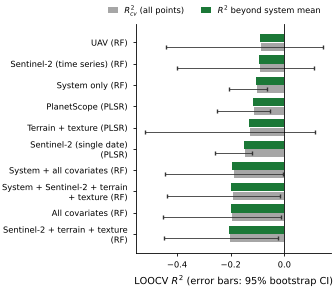

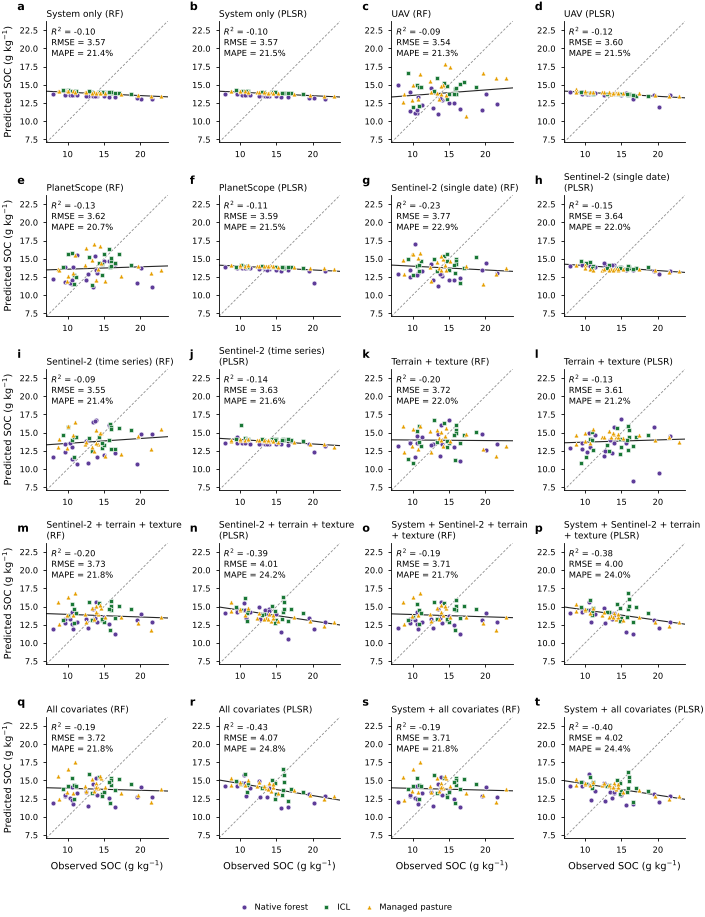

In [13]:
bloco('COT_0-10', w)

### 5.2 MAOC

,alvo,conjunto,modelo,n,p,R2_cv,R2_IC95_inf,R2_IC95_sup,R2_dentro,RMSE_cv,MAPE_cv,vies
0,COM_0-10,Só o sistema,RF,60,3,-0.099,-0.214,-0.073,-0.105,3.480,21.346,0.001
1,COM_0-10,Só o sistema,PLSR,60,3,-0.101,-0.218,-0.074,-0.107,3.483,21.402,0.004
2,COM_0-10,Drone,RF,60,3,-0.121,-0.478,0.109,-0.127,3.514,21.456,0.026
3,COM_0-10,Drone,PLSR,60,3,-0.077,-0.198,-0.041,-0.083,3.445,21.070,-0.003
4,COM_0-10,Planet,RF,60,3,-0.147,-0.392,0.033,-0.154,3.556,20.479,-0.098
5,COM_0-10,Planet,PLSR,60,3,-0.135,-0.250,-0.101,-0.141,3.536,21.505,-0.026
6,COM_0-10,Sentinel-2 (data),RF,60,17,-0.258,-0.532,-0.110,-0.265,3.723,23.078,-0.001
7,COM_0-10,Sentinel-2 (data),PLSR,60,17,-0.112,-0.226,-0.076,-0.118,3.501,21.146,-0.029
8,COM_0-10,Sentinel-2 (série),RF,60,5,-0.101,-0.447,0.104,-0.108,3.484,21.447,-0.017
9,COM_0-10,Sentinel-2 (série),PLSR,60,5,-0.150,-0.310,-0.089,-0.156,3.559,21.882,-0.002


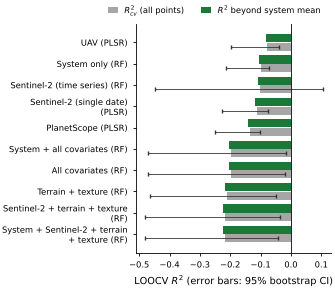

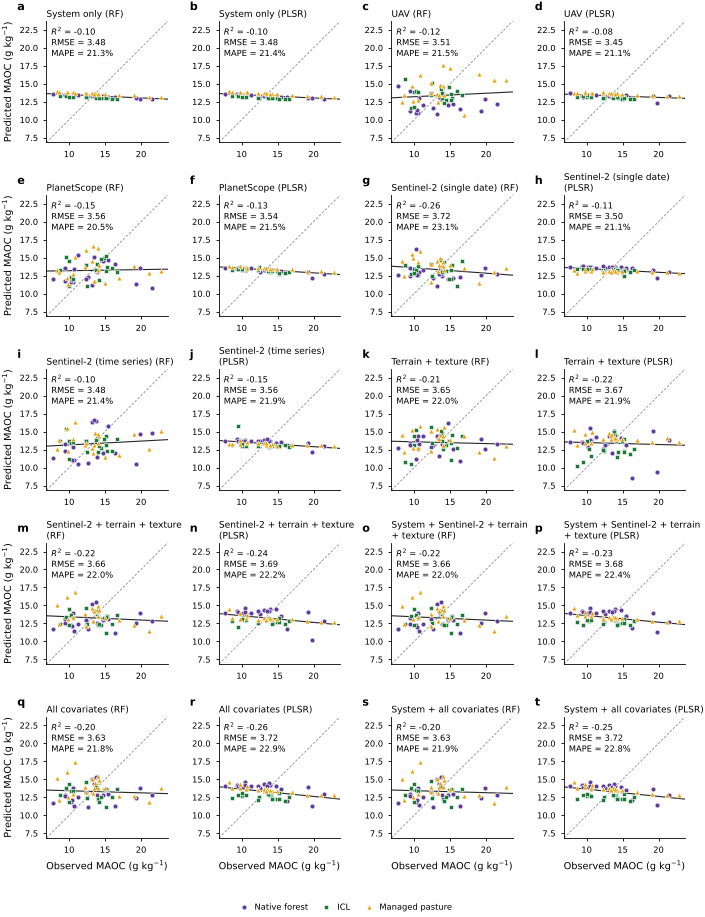

In [14]:
bloco('COM_0-10', w)

### 5.3 POC

,alvo,conjunto,modelo,n,p,R2_cv,R2_IC95_inf,R2_IC95_sup,R2_dentro,RMSE_cv,MAPE_cv,vies
0,COP_0-10,Só o sistema,RF,60,3,0.438,0.258,0.511,-0.110,0.368,69.068,0.005
1,COP_0-10,Só o sistema,PLSR,60,3,0.439,0.281,0.510,-0.108,0.367,68.658,0.000
2,COP_0-10,Drone,RF,60,3,0.288,-0.136,0.423,-0.407,0.414,90.797,0.001
3,COP_0-10,Drone,PLSR,60,3,0.453,0.277,0.514,-0.080,0.363,80.784,-0.001
4,COP_0-10,Planet,RF,60,3,0.376,-0.129,0.539,-0.233,0.388,80.153,0.011
5,COP_0-10,Planet,PLSR,60,3,0.144,-0.137,0.234,-0.691,0.454,126.444,-0.021
6,COP_0-10,Sentinel-2 (data),RF,60,17,0.462,0.174,0.608,-0.062,0.360,82.109,-0.009
7,COP_0-10,Sentinel-2 (data),PLSR,60,17,0.189,-0.221,0.375,-0.601,0.442,116.639,0.007
8,COP_0-10,Sentinel-2 (série),RF,60,5,0.701,0.248,0.826,0.409,0.268,71.903,-0.022
9,COP_0-10,Sentinel-2 (série),PLSR,60,5,0.514,0.198,0.594,0.041,0.342,75.045,-0.004


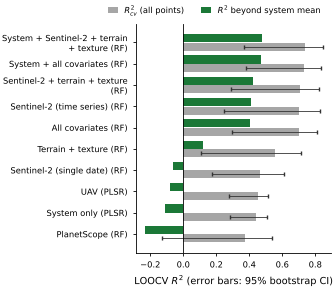

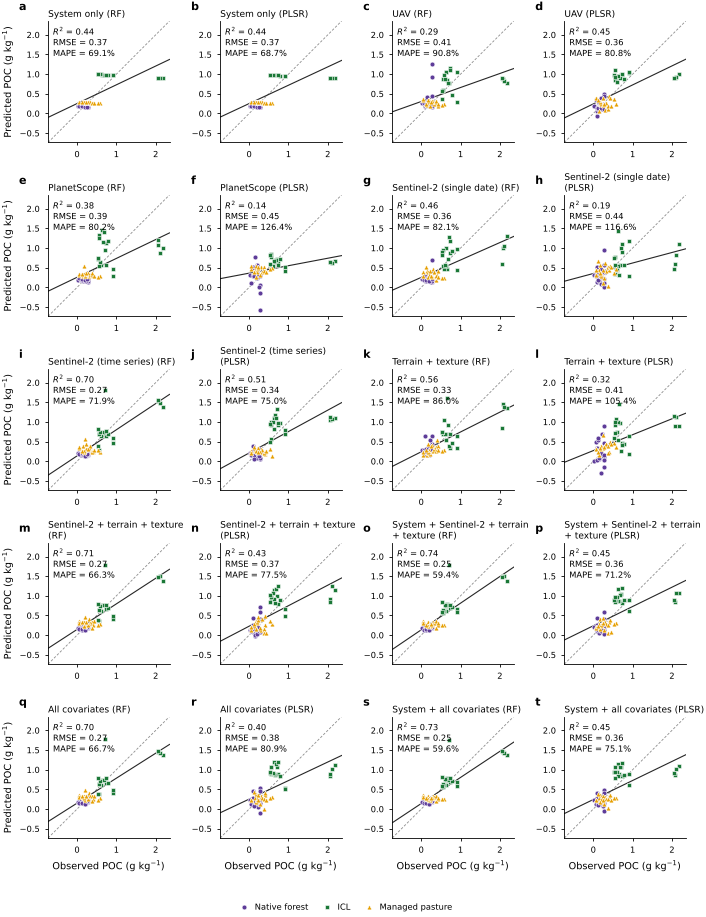

In [15]:
bloco('COP_0-10', w)

### 5.4 Combined table

In [16]:
tab = pd.concat(res.values(), ignore_index=True)
tab.to_excel(os.path.join(OUT, 'Resultados_ML_reanalise.xlsx'), index=False)
display(tab.round(3))

,alvo,conjunto,modelo,n,p,R2_cv,R2_IC95_inf,R2_IC95_sup,R2_dentro,RMSE_cv,MAPE_cv,vies
0,COT_0-10,Só o sistema,RF,60,3,-0.101,-0.205,-0.065,-0.106,3.568,21.395,0.006
1,COT_0-10,Só o sistema,PLSR,60,3,-0.103,-0.206,-0.071,-0.108,3.571,21.472,-0.001
2,COT_0-10,Drone,RF,60,3,-0.086,-0.442,0.142,-0.091,3.545,21.343,0.031
3,COT_0-10,Drone,PLSR,60,3,-0.120,-0.244,-0.075,-0.125,3.599,21.528,-0.037
4,COT_0-10,Planet,RF,60,3,-0.134,-0.390,0.058,-0.140,3.622,20.674,-0.118
5,COT_0-10,Planet,PLSR,60,3,-0.113,-0.251,-0.054,-0.118,3.588,21.496,-0.030
6,COT_0-10,Sentinel-2 (data),RF,60,17,-0.230,-0.486,-0.063,-0.236,3.772,22.911,-0.024
7,COT_0-10,Sentinel-2 (data),PLSR,60,17,-0.147,-0.260,-0.119,-0.152,3.642,22.027,-0.008
8,COT_0-10,Sentinel-2 (série),RF,60,5,-0.090,-0.401,0.110,-0.095,3.550,21.376,-0.026
9,COT_0-10,Sentinel-2 (série),PLSR,60,5,-0.138,-0.273,-0.071,-0.143,3.628,21.580,0.008


### 5.5 R² with all points × within systems
The grey line shows how much of the accuracy comes only from recognising the system.

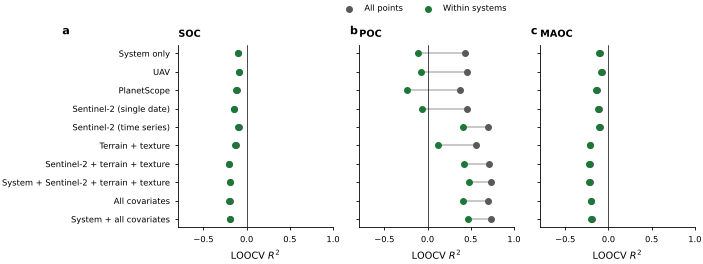

In [17]:
R.fig_halteres(tab, OUT); plt.show()

### 5.6 SHAP values of POC (Random Forest with the Sentinel-2 time series)

,|SHAP| médio
S2s_NDVI_dp,0.290
S2s_NDVI_chuva,0.049
S2s_BSI_seca,0.013
S2s_freq_solo_exposto,0.009
S2s_NDVI_seca,0.005


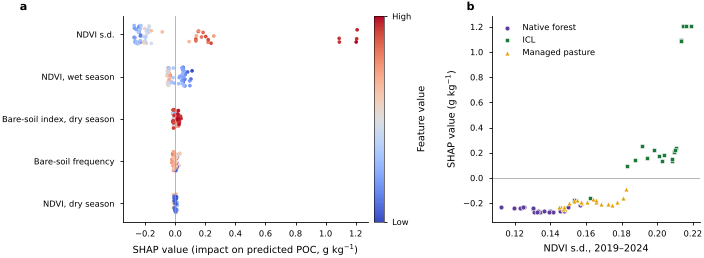

In [18]:
sh = R.shap_serie(w, 'COP_0-10')
display(sh['shap'].abs().mean().sort_values(ascending=False).round(3).to_frame('|SHAP| médio'))
R.fig_shap(sh, OUT); plt.show()

### 5.7 Predicted POC map (10 m)
Sentinel-2 time series on a 10 m grid (`../data/s2_series_grid_10m.csv`); the Random Forest is applied within the three areas, with uncertainty as the standard deviation among trees. × marks pixels outside the calibration range.

9670 pixels nas áreas; 14.3% fora da faixa de calibração


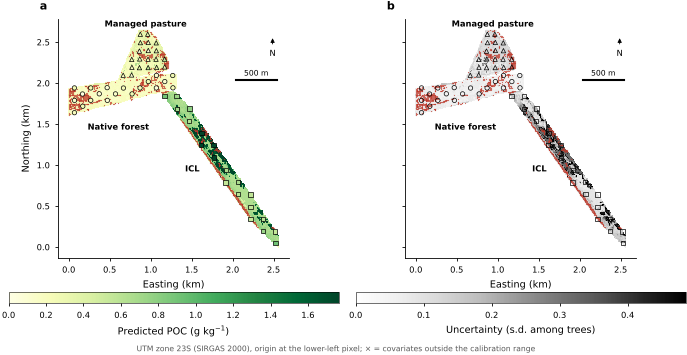

In [19]:
g = R.grade_serie_s2(dict(PASTA=DATA), w, saida='s2_series_grid_10m.csv')
gp = R.mapa_predito(w, g, 'COP_0-10')
gp.to_csv(os.path.join(OUT, 'mapa_COP_predito.csv'), index=False)
R.fig_mapa(gp, w, OUT, 'COP_0-10'); plt.show()

### 5.8 Layers 10–20 and 20–30 cm
The sensors see only the surface: if a model 'predicts' POC at 20–30 cm, the accuracy can only come from the contrast between systems.

In [20]:
conj_sup = {k: v for k, v in R.conjuntos_padrao(w).items() if k in ['Só o sistema', 'Drone', 'Planet', 'Sentinel-2 (série)', 'Sistema + Sentinel-2 + relevo + textura']}
res_cam = []
for alvo in [f'{v}_{c}' for v in ['COT', 'COP', 'COM'] for c in ['10-20', '20-30']]:
    r, _ = R.avaliar(w, alvo, conj_sup); res_cam.append(r)
tab_cam = pd.concat(res_cam, ignore_index=True)
tab_cam.to_excel(os.path.join(OUT, 'Resultados_ML_camadas.xlsx'), index=False)
display(tab_cam.loc[tab_cam.groupby(['alvo', 'conjunto']).R2_cv.idxmax(), ['alvo', 'conjunto', 'modelo', 'R2_cv', 'R2_dentro', 'RMSE_cv']].round(3))

,alvo,conjunto,modelo,R2_cv,R2_dentro,RMSE_cv
43,COM_10-20,Drone,PLSR,-0.007,-0.323,2.605
44,COM_10-20,Planet,RF,0.235,-0.006,2.272
47,COM_10-20,Sentinel-2 (série),PLSR,0.169,-0.092,2.367
48,COM_10-20,Sistema + Sentinel-2 + relevo + textura,RF,0.216,-0.030,2.299
40,COM_10-20,Só o sistema,RF,0.161,-0.102,2.378
53,COM_20-30,Drone,PLSR,-0.113,-0.136,2.212
54,COM_20-30,Planet,RF,-0.084,-0.107,2.184
56,COM_20-30,Sentinel-2 (série),RF,-0.116,-0.140,2.216
58,COM_20-30,Sistema + Sentinel-2 + relevo + textura,RF,-0.053,-0.075,2.152
50,COM_20-30,Só o sistema,RF,-0.082,-0.105,2.182


### 5.9 Between-system variance × R² (central result)
η² is the fraction of the variance of each variable that lies between systems. If the R² of the best remote sensing model tracks η² (1:1 line), including at 20–30 cm, and R² within systems stays near zero, the accuracy comes from the contrast between systems and not from carbon within the field.

,alvo,n,eta2,eta2_IC95_inf,eta2_IC95_sup,CV_dentro_medio_pct
0,COT_0-10,60,0.005,0.001,0.156,24.927
1,COT_10-20,60,0.235,0.081,0.469,18.571
2,COT_20-30,60,0.033,0.002,0.207,21.062
3,COP_0-10,60,0.494,0.448,0.606,53.345
4,COP_10-20,60,0.538,0.350,0.729,34.365
5,COP_20-30,60,0.423,0.275,0.633,35.474
6,COM_0-10,60,0.006,0.001,0.136,24.891
7,COM_10-20,60,0.239,0.085,0.476,18.968
8,COM_20-30,60,0.021,0.002,0.180,21.997


,alvo,eta2,eta2_IC95_inf,eta2_IC95_sup,R2_so_sistema,melhor_conjunto,modelo,R2_cv,R2_dentro
0,COM_0-10,0.006,0.001,0.136,-0.099,Drone,PLSR,-0.077,-0.083
1,COM_10-20,0.239,0.085,0.476,0.161,Planet,RF,0.235,-0.006
2,COM_20-30,0.021,0.002,0.180,-0.082,Planet,RF,-0.084,-0.107
3,COP_0-10,0.494,0.448,0.606,0.439,Sentinel-2 + relevo + textura,RF,0.707,0.422
4,COP_10-20,0.538,0.350,0.729,0.488,Drone,PLSR,0.474,-0.138
5,COP_20-30,0.423,0.275,0.633,0.361,Planet,PLSR,0.309,-0.198
6,COT_0-10,0.005,0.001,0.156,-0.101,Drone,RF,-0.086,-0.091
7,COT_10-20,0.235,0.081,0.469,0.156,Planet,RF,0.231,-0.005
8,COT_20-30,0.033,0.002,0.207,-0.062,Planet,RF,-0.059,-0.095


Correlação entre eta² e R²cv: 0.95


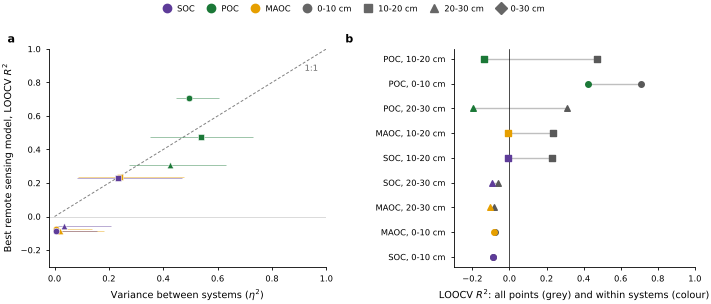

In [21]:
alvos_all = [f'{v}_{c}' for v in ['COT', 'COP', 'COM'] for c in ['0-10', '10-20', '20-30']]
part = R.particao_variancia(w, alvos_all)
ti = R.tabela_inflacao(pd.concat([tab, tab_cam], ignore_index=True), part)
ti.to_excel(os.path.join(OUT, 'Resultados_inflacao_R2.xlsx'), index=False)
display(part.round(3)); display(ti.round(3))
print('Correlação entre eta² e R²cv:', round(np.corrcoef(ti.eta2, ti.R2_cv)[0, 1], 2))
R.fig_inflacao(ti, OUT, 'Fig_inflacao_R2'); plt.show()

## 6. Sensitivity: POC without ICL points 6–9 (0–10 cm)

,alvo,conjunto,modelo,n,p,R2_cv,R2_IC95_inf,R2_IC95_sup,R2_dentro,RMSE_cv,MAPE_cv,vies
0,COP_0-10,Só o sistema,RF,56,3,0.725,0.591,0.805,-0.117,0.123,59.243,-0.001
1,COP_0-10,Só o sistema,PLSR,56,3,0.726,0.597,0.806,-0.111,0.123,59.703,0.001
2,COP_0-10,Drone,RF,56,3,0.406,0.161,0.603,-1.411,0.181,80.504,0.000
3,COP_0-10,Drone,PLSR,56,3,0.687,0.505,0.795,-0.273,0.131,64.843,-0.000
4,COP_0-10,Planet,RF,56,3,0.536,0.301,0.725,-0.882,0.160,65.128,-0.009
5,COP_0-10,Planet,PLSR,56,3,0.173,-0.086,0.364,-2.357,0.213,98.704,0.006
6,COP_0-10,Sentinel-2 (data),RF,56,17,0.534,0.298,0.692,-0.892,0.160,73.658,-0.008
7,COP_0-10,Sentinel-2 (data),PLSR,56,17,0.319,0.025,0.531,-1.763,0.193,84.712,-0.004
8,COP_0-10,Sentinel-2 (série),RF,56,5,0.528,0.311,0.685,-0.915,0.161,70.432,-0.012
9,COP_0-10,Sentinel-2 (série),PLSR,56,5,0.626,0.474,0.733,-0.517,0.143,67.804,-0.001


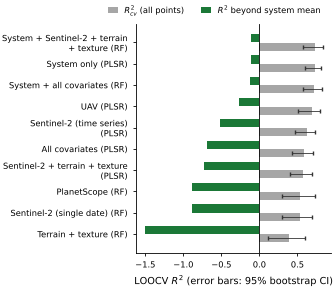

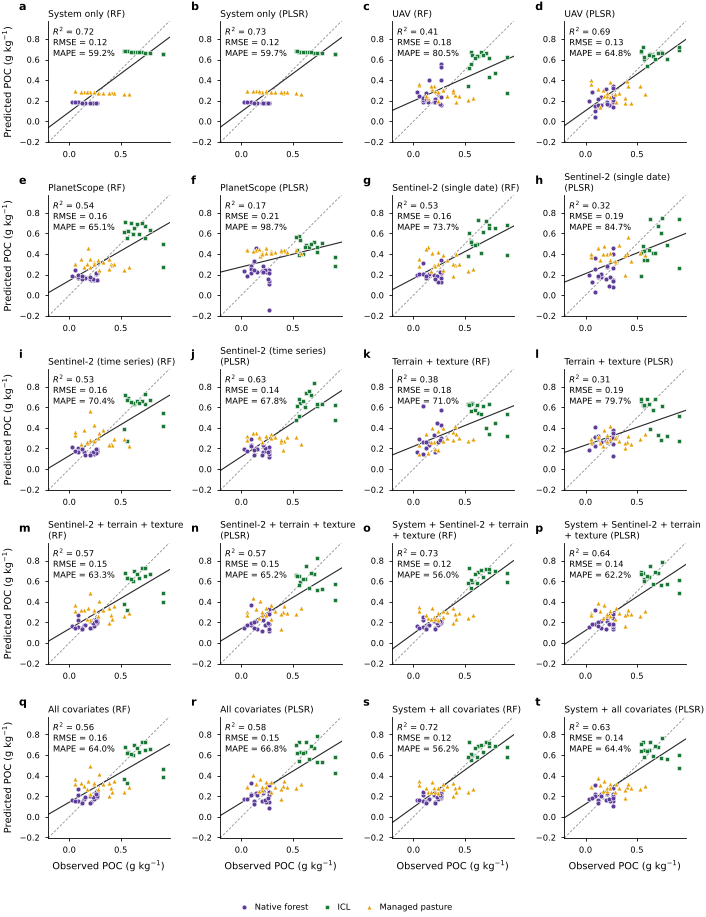

In [22]:
sens, p_sens = R.avaliar(w, 'COP_0-10', R.conjuntos_padrao(w), excluir_flag=True)
sens.to_excel(os.path.join(OUT, 'Resultados_ML_sensibilidade.xlsx'), index=False)
display(sens.round(3))
R.fig_r2(sens.assign(alvo='COP_0-10 sem 6-9'), OUT, 'COP_0-10 sem 6-9'); plt.show()
R.fig_obs_pred(p_sens, 'COP_0-10', OUT, nome='Fig_obs_pred_COP_0-10_sem_pontos_6-9'); plt.show()

## 7. Temporal validation: calibrate in the dry season, predict the wet season (0–10 cm)
Transfer is assessed at two levels: **within systems** (`r_dentro_val`, `R2_dentro_val`) and **at the system level** (`erro_media_*_%`, error of the predicted mean of each system; `ordem_sistemas_ok`, whether the ranking of the systems is kept). The Sentinel-2 time series, terrain and texture are the same in both seasons; only the single-date scene changes (`S2_` → `S2c_`).

In [23]:
w = R.adicionar_chuvoso(w, DATA)
val = []

### 7.1 MAOC

,alvo,conjunto,modelo,n_cal,n_val,R2_val,R2_IC95_inf,R2_IC95_sup,r_val,R2_dentro_val,r_dentro_val,RMSE_val,MAPE_val,vies,ordem_sistemas_ok,erro_media_ILP8_%,erro_media_MN_%,erro_media_PM_%
0,COM_0-10 -> chuvoso,Só o sistema,RF,60,60,-0.152,-0.618,0.007,0.250,-0.243,NaN,3.218,24.647,1.289,True,19.581,6.903,6.765
1,COM_0-10 -> chuvoso,Só o sistema,PLSR,60,60,-0.146,-0.606,0.011,0.242,-0.236,NaN,3.208,24.581,1.268,True,19.336,6.524,6.843
2,COM_0-10 -> chuvoso,Sentinel-2 (data),RF,60,60,-0.879,-1.966,-0.411,-0.201,-1.027,-0.038,4.108,33.091,2.192,False,42.363,3.964,11.338
3,COM_0-10 -> chuvoso,Sentinel-2 (data),PLSR,60,60,-0.278,-0.779,-0.104,-0.343,-0.378,-0.282,3.388,25.456,1.274,False,24.898,7.415,1.350
4,COM_0-10 -> chuvoso,Sentinel-2 (série),RF,60,60,-0.003,-0.596,0.302,0.447,-0.082,0.446,3.001,22.407,1.282,True,20.655,6.091,6.462
5,COM_0-10 -> chuvoso,Sentinel-2 (série),PLSR,60,60,-0.164,-0.624,-0.003,0.129,-0.256,-0.081,3.234,24.377,1.268,False,19.556,9.493,3.752
6,COM_0-10 -> chuvoso,Relevo + textura,RF,60,60,-0.072,-0.664,0.209,0.386,-0.156,0.379,3.103,23.733,1.356,False,21.268,5.940,7.835
7,COM_0-10 -> chuvoso,Relevo + textura,PLSR,60,60,-0.122,-0.659,0.105,0.271,-0.211,0.206,3.175,24.310,1.268,True,17.439,5.438,9.528
8,COM_0-10 -> chuvoso,Sentinel-2 + relevo + textura,RF,60,60,-0.273,-1.028,0.073,0.320,-0.373,0.396,3.381,26.615,1.773,False,29.597,4.329,12.067
9,COM_0-10 -> chuvoso,Sentinel-2 + relevo + textura,PLSR,60,60,-0.331,-0.873,-0.129,-0.238,-0.436,-0.201,3.458,25.640,1.279,False,24.324,9.801,-0.367


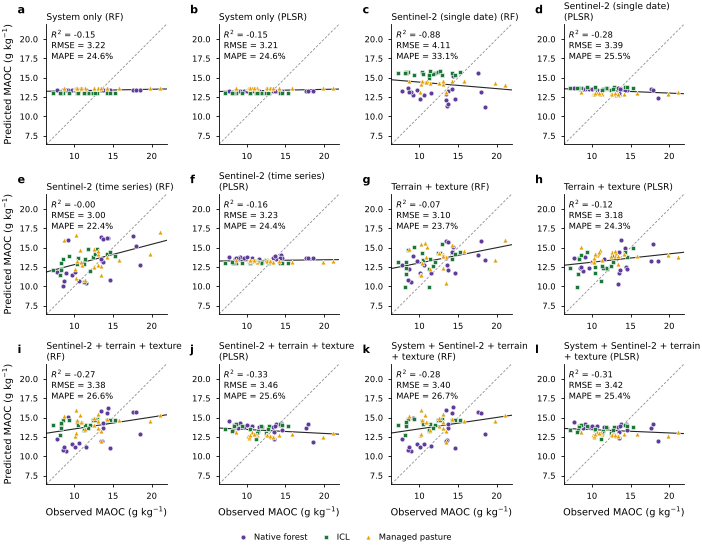

In [24]:
r, p = R.validar_no_tempo(w, 'COM_0-10', 'COM_0-10_ch', R.conjuntos_padrao(w)); val.append(r)
display(r.round(3))
if p: R.fig_obs_pred(p, 'COM_0-10', OUT, nome='Fig_obs_pred_chuvoso_COM_0-10'); plt.show()

### 7.2 SOC

,alvo,conjunto,modelo,n_cal,n_val,R2_val,R2_IC95_inf,R2_IC95_sup,r_val,R2_dentro_val,r_dentro_val,RMSE_val,MAPE_val,vies,ordem_sistemas_ok,erro_media_ILP8_%,erro_media_MN_%,erro_media_PM_%
0,COT_0-10 -> chuvoso,Só o sistema,RF,60,60,-0.258,-0.803,-0.067,-0.138,-0.348,NaN,3.333,24.927,1.432,False,23.900,6.114,6.135
1,COT_0-10 -> chuvoso,Só o sistema,PLSR,60,60,-0.254,-0.792,-0.069,-0.169,-0.343,NaN,3.327,24.787,1.403,False,23.934,5.985,5.572
2,COT_0-10 -> chuvoso,Sentinel-2 (data),RF,60,60,-0.499,-1.215,-0.210,-0.156,-0.607,0.005,3.638,27.629,1.574,False,32.000,2.224,6.168
3,COT_0-10 -> chuvoso,Sentinel-2 (data),PLSR,60,60,-0.088,-0.454,0.026,0.090,-0.166,-0.161,3.099,21.726,0.917,False,14.151,7.480,1.473
4,COT_0-10 -> chuvoso,Sentinel-2 (série),RF,60,60,-0.071,-0.716,0.251,0.435,-0.148,0.476,3.075,22.409,1.409,False,24.151,5.541,5.949
5,COT_0-10 -> chuvoso,Sentinel-2 (série),PLSR,60,60,-0.256,-0.801,-0.068,-0.150,-0.346,-0.018,3.330,24.933,1.403,False,23.998,5.650,5.842
6,COT_0-10 -> chuvoso,Relevo + textura,RF,60,60,-0.167,-0.810,0.144,0.357,-0.251,0.399,3.210,23.664,1.499,False,24.993,5.906,6.918
7,COT_0-10 -> chuvoso,Relevo + textura,PLSR,60,60,-0.187,-0.778,0.064,0.258,-0.272,0.226,3.238,24.298,1.403,False,19.422,5.817,9.635
8,COT_0-10 -> chuvoso,Sentinel-2 + relevo + textura,RF,60,60,-0.226,-0.903,0.078,0.301,-0.314,0.417,3.290,24.698,1.607,False,28.720,3.452,8.557
9,COT_0-10 -> chuvoso,Sentinel-2 + relevo + textura,PLSR,60,60,-0.090,-0.355,0.122,0.174,-0.168,0.023,3.102,19.978,-0.524,False,-6.366,-0.840,-5.653


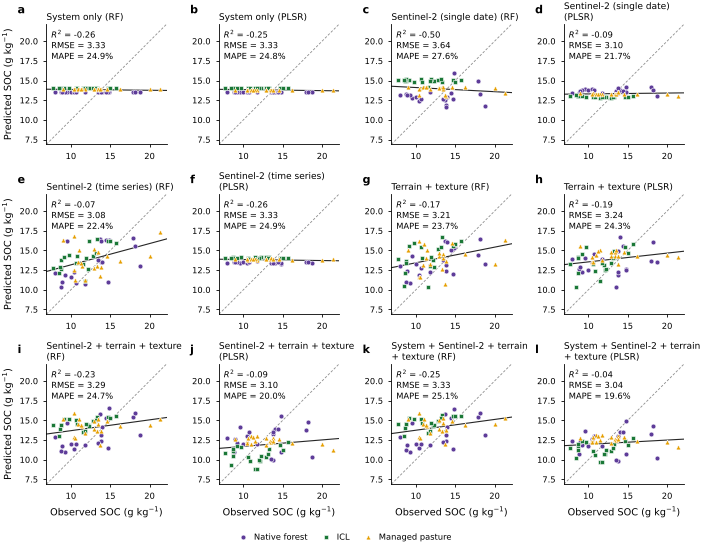

In [25]:
r, p = R.validar_no_tempo(w, 'COT_0-10', 'COT_0-10_ch', R.conjuntos_padrao(w)); val.append(r)
display(r.round(3))
if p: R.fig_obs_pred(p, 'COT_0-10', OUT, nome='Fig_obs_pred_chuvoso_COT_0-10'); plt.show()

### 7.3 POC

,alvo,conjunto,modelo,n_cal,n_val,R2_val,R2_IC95_inf,R2_IC95_sup,r_val,R2_dentro_val,r_dentro_val,RMSE_val,MAPE_val,vies,ordem_sistemas_ok,erro_media_ILP8_%,erro_media_MN_%,erro_media_PM_%
0,COP_0-10 -> chuvoso,Só o sistema,RF,60,60,-9.569,-17.855,-5.042,0.499,-14.443,NaN,0.345,76.998,0.142,True,140.002,-31.660,-17.311
1,COP_0-10 -> chuvoso,Só o sistema,PLSR,60,60,-8.903,-16.730,-4.656,0.499,-13.471,NaN,0.334,75.276,0.135,True,134.997,-31.743,-17.777
2,COP_0-10 -> chuvoso,Sentinel-2 (data),RF,60,60,-4.566,-8.985,-2.313,-0.249,-7.133,-0.081,0.251,77.743,0.087,False,-23.524,80.986,42.093
3,COP_0-10 -> chuvoso,Sentinel-2 (data),PLSR,60,60,-95.458,-164.165,-58.256,-0.390,-139.945,-0.038,1.043,228.118,-0.554,False,-418.115,-30.508,34.464
4,COP_0-10 -> chuvoso,Sentinel-2 (série),RF,60,60,-13.709,-30.348,-4.541,0.472,-20.493,0.154,0.407,68.581,0.130,True,127.618,-31.793,-13.061
5,COP_0-10 -> chuvoso,Sentinel-2 (série),PLSR,60,60,-10.658,-19.944,-5.746,0.488,-16.035,0.101,0.363,78.903,0.135,True,138.671,-28.411,-24.655
6,COP_0-10 -> chuvoso,Relevo + textura,RF,60,60,-11.892,-27.408,-3.854,0.406,-17.837,0.093,0.381,70.011,0.142,True,117.344,0.882,-15.423
7,COP_0-10 -> chuvoso,Relevo + textura,PLSR,60,60,-9.030,-17.845,-4.440,0.402,-13.655,0.062,0.336,87.993,0.135,True,97.478,-3.490,5.169
8,COP_0-10 -> chuvoso,Sentinel-2 + relevo + textura,RF,60,60,-12.076,-27.490,-3.514,0.483,-18.106,0.187,0.384,60.717,0.140,True,115.644,-20.822,1.539
9,COP_0-10 -> chuvoso,Sentinel-2 + relevo + textura,PLSR,60,60,-7.931,-15.231,-4.113,0.407,-12.050,0.069,0.317,87.721,-0.211,True,-13.196,-124.732,-73.845


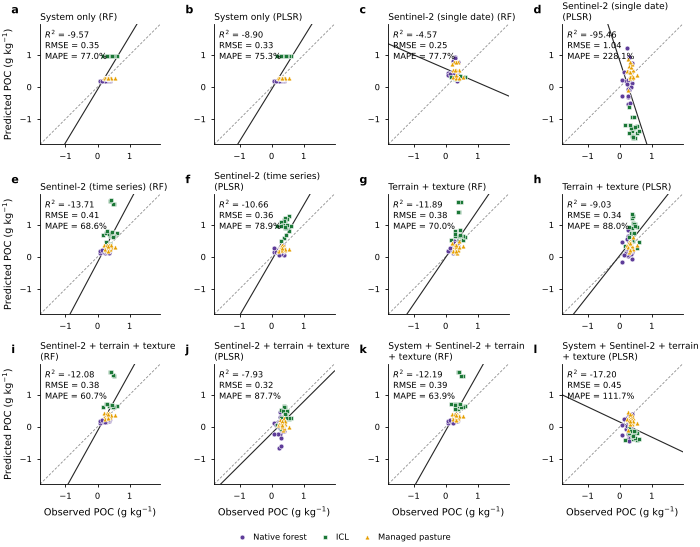

In [26]:
r, p = R.validar_no_tempo(w, 'COP_0-10', 'COP_0-10_ch', R.conjuntos_padrao(w)); val.append(r)
display(r.round(3))
if p: R.fig_obs_pred(p, 'COP_0-10', OUT, nome='Fig_obs_pred_chuvoso_COP_0-10'); plt.show()

### 7.4 POC without ICL points 6–9 in the calibration

In [27]:
r, _ = R.validar_no_tempo(w, 'COP_0-10', 'COP_0-10_ch', R.conjuntos_padrao(w), excluir_flag=True)
r['alvo'] = 'COP_0-10 -> chuvoso (sem 6-9 na calibração)'; val.append(r)
display(r.round(3))

,alvo,conjunto,modelo,n_cal,n_val,R2_val,R2_IC95_inf,R2_IC95_sup,r_val,R2_dentro_val,r_dentro_val,RMSE_val,MAPE_val,vies,ordem_sistemas_ok,erro_media_ILP8_%,erro_media_MN_%,erro_media_PM_%
0,COP_0-10 -> chuvoso (sem 6-9 na calibração),Só o sistema,RF,56,56,-1.866,-4.109,-0.627,0.482,-3.012,NaN,0.181,49.613,0.024,True,66.905,-31.896,-18.606
1,COP_0-10 -> chuvoso (sem 6-9 na calibração),Só o sistema,PLSR,56,56,-1.823,-4.036,-0.602,0.484,-2.952,NaN,0.180,49.283,0.025,True,66.351,-31.743,-17.777
2,COP_0-10 -> chuvoso (sem 6-9 na calibração),Sentinel-2 (data),RF,56,56,-1.025,-1.809,-0.623,-0.297,-1.835,-0.075,0.152,51.724,-0.004,False,-34.448,38.765,-0.593
3,COP_0-10 -> chuvoso (sem 6-9 na calibração),Sentinel-2 (data),PLSR,56,56,-9.187,-15.897,-5.601,-0.307,-13.261,-0.033,0.342,84.047,-0.135,False,-141.085,3.878,18.964
4,COP_0-10 -> chuvoso (sem 6-9 na calibração),Sentinel-2 (série),RF,56,56,-1.575,-3.745,-0.393,0.517,-2.604,0.178,0.172,45.957,0.022,True,59.272,-31.709,-13.520
5,COP_0-10 -> chuvoso (sem 6-9 na calibração),Sentinel-2 (série),PLSR,56,56,-1.556,-3.639,-0.386,0.487,-2.578,0.069,0.171,45.911,0.025,True,59.131,-27.660,-14.111
6,COP_0-10 -> chuvoso (sem 6-9 na calibração),Relevo + textura,RF,56,56,-1.025,-2.643,-0.183,0.464,-1.835,0.159,0.152,45.989,0.027,True,45.337,-4.726,-16.640
7,COP_0-10 -> chuvoso (sem 6-9 na calibração),Relevo + textura,PLSR,56,56,-1.099,-2.568,-0.294,0.305,-1.939,-0.092,0.155,45.816,0.025,True,34.371,5.012,-15.714
8,COP_0-10 -> chuvoso (sem 6-9 na calibração),Sentinel-2 + relevo + textura,RF,56,56,-0.709,-2.174,0.099,0.571,-1.393,0.296,0.140,37.859,0.027,True,44.291,-22.491,-2.585
9,COP_0-10 -> chuvoso (sem 6-9 na calibração),Sentinel-2 + relevo + textura,PLSR,56,56,-7.849,-13.159,-4.751,-0.193,-11.388,-0.049,0.319,75.475,-0.208,False,-122.690,-53.952,-13.422


### 7.5 Combined table (best model of each set)

In [28]:
val_tab = pd.concat(val, ignore_index=True)
val_tab.to_excel(os.path.join(OUT, 'Resultados_validacao_chuvoso.xlsx'), index=False)
cols = ['alvo', 'conjunto', 'modelo', 'R2_val', 'r_val', 'r_dentro_val', 'R2_dentro_val', 'ordem_sistemas_ok'] + [c for c in val_tab.columns if c.startswith('erro_media_')]
melhor = val_tab.loc[val_tab.groupby(['alvo', 'conjunto']).R2_val.idxmax(), cols]
display(melhor.round(3))

,alvo,conjunto,modelo,R2_val,r_val,r_dentro_val,R2_dentro_val,ordem_sistemas_ok,erro_media_ILP8_%,erro_media_MN_%,erro_media_PM_%
6,COM_0-10 -> chuvoso,Relevo + textura,RF,-0.072,0.386,0.379,-0.156,False,21.268,5.940,7.835
3,COM_0-10 -> chuvoso,Sentinel-2 (data),PLSR,-0.278,-0.343,-0.282,-0.378,False,24.898,7.415,1.350
4,COM_0-10 -> chuvoso,Sentinel-2 (série),RF,-0.003,0.447,0.446,-0.082,True,20.655,6.091,6.462
8,COM_0-10 -> chuvoso,Sentinel-2 + relevo + textura,RF,-0.273,0.320,0.396,-0.373,False,29.597,4.329,12.067
10,COM_0-10 -> chuvoso,Sistema + Sentinel-2 + relevo + textura,RF,-0.283,0.308,0.390,-0.384,False,29.997,4.241,11.754
1,COM_0-10 -> chuvoso,Só o sistema,PLSR,-0.146,0.242,NaN,-0.236,True,19.336,6.524,6.843
31,COP_0-10 -> chuvoso,Relevo + textura,PLSR,-9.030,0.402,0.062,-13.655,True,97.478,-3.490,5.169
26,COP_0-10 -> chuvoso,Sentinel-2 (data),RF,-4.566,-0.249,-0.081,-7.133,False,-23.524,80.986,42.093
29,COP_0-10 -> chuvoso,Sentinel-2 (série),PLSR,-10.658,0.488,0.101,-16.035,True,138.671,-28.411,-24.655
33,COP_0-10 -> chuvoso,Sentinel-2 + relevo + textura,PLSR,-7.931,0.407,0.069,-12.050,True,-13.196,-124.732,-73.845


## 8. Repeatability dry × wet season (same points, 0–10 cm)
If the value of a point in the dry season does not predict that of the same point in the wet season within the system, the variable does not repeat within the system, and no sensor can predict it there.

,variavel,sistema,n,seco,chuvoso,variacao_pct,p_t,p_wilcoxon,r,p_r,rho
0,COT,ILP8,20,14.006,11.342,-19.018,0.000,0.000,0.645,0.002,0.726
1,COT,MN,20,13.488,12.755,-5.429,0.305,0.277,0.613,0.004,0.645
2,COT,PM,20,13.935,13.122,-5.836,0.402,0.674,0.289,0.216,0.174
3,COT,Dentro dos sistemas,60,NaN,NaN,NaN,NaN,NaN,0.490,0.000,0.533
4,COP,ILP8,20,0.956,0.407,-57.446,0.001,0.000,0.066,0.784,0.128
5,COP,MN,20,0.178,0.261,46.506,0.003,0.002,0.246,0.295,0.360
6,COP,PM,20,0.283,0.344,21.621,0.128,0.126,-0.084,0.724,-0.015
7,COP,Dentro dos sistemas,60,NaN,NaN,NaN,NaN,NaN,0.050,0.705,0.091
8,COM,ILP8,20,13.050,10.936,-16.203,0.001,0.001,0.520,0.019,0.540
9,COM,MN,20,13.310,12.494,-6.125,0.258,0.245,0.607,0.005,0.623


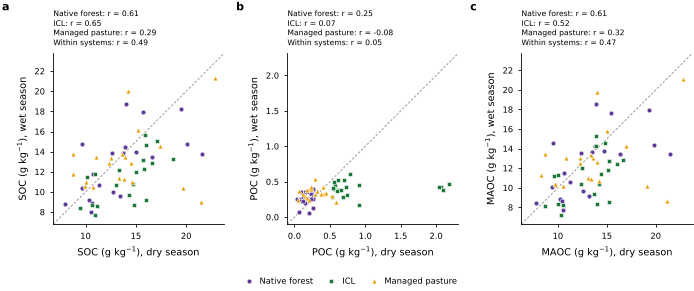

In [29]:
rep = R.repetibilidade(w)
rep.to_csv(os.path.join(OUT, 'repetibilidade_seco_chuvoso_0-10.csv'), index=False)
display(rep.round(3))
R.fig_repetibilidade(w, OUT); plt.show()

## 9. Sensitivity to the laboratory correction
Main Random Forest models with the corrected values and with the uncorrected values (Online Resource 1).

In [30]:
w_dig = R.tabela_ponto(R.carregar(DATA, versao='uncorrected'))
principais = ['Só o sistema', 'Sentinel-2 (série)', 'Sistema + Sentinel-2 + relevo + textura']
sens_lab = []
for alvo in ['COT_0-10', 'COP_0-10', 'COM_0-10']:
    for versao, ww in [('corrected', w), ('uncorrected', w_dig)]:
        conj = {k: v for k, v in R.conjuntos_padrao(ww).items() if k in principais}
        r, _ = R.avaliar(ww, alvo, conj, modelos=('RF',)); r['versao'] = versao; sens_lab.append(r)
sens_lab = pd.concat(sens_lab, ignore_index=True)
sens_lab.to_excel(os.path.join(OUT, 'Resultados_sensibilidade_correcao_lab.xlsx'), index=False)
display(sens_lab.pivot_table(index=['alvo', 'conjunto'], columns='versao', values=['R2_cv', 'R2_dentro']).round(3))

180 amostras do período seco (uncorrected); COP marcado (sensibilidade): [['MN', 1, '20-30cm', 0.062], ['MN', 7, '20-30cm', 0.187], ['MN', 8, '20-30cm', 0.658], ['ILP8', 6, '0-10cm', 2.209], ['ILP8', 7, '0-10cm', 2.334], ['ILP8', 8, '0-10cm', 2.241], ['ILP8', 9, '0-10cm', 2.185]]


R2_cv              \
versao                                           corrected uncorrected   
alvo     conjunto                                                        
COM_0-10 Sentinel-2 (série)                         -0.101      -0.073   
         Sistema + Sentinel-2 + relevo + textura    -0.218      -0.238   
         Só o sistema                               -0.099      -0.101   
COP_0-10 Sentinel-2 (série)                          0.701       0.701   
         Sistema + Sentinel-2 + relevo + textura     0.736       0.738   
         Só o sistema                                0.438       0.439   
COT_0-10 Sentinel-2 (série)                         -0.090       0.012   
         Sistema + Sentinel-2 + relevo + textura    -0.192      -0.152   
         Só o sistema                               -0.101      -0.080   

                                                 R2_dentro              
versao                                           corrected uncorrected  
alvo     conjunto                                                       
COM_0-10 Sentinel-2 (série)                         -0.108      -0.078  
         Sistema + Sentinel-2 + relevo + textura    -0.225      -0.243  
         Só o sistema                               -0.105      -0.105  
COP_0-10 Sentinel-2 (série)                          0.409       0.409  
         Sistema + Sentinel-2 + relevo + textura     0.479       0.481  
         Só o sistema                               -0.110      -0.110  
COT_0-10 Sentinel-2 (série)                         -0.095      -0.011  
         Sistema + Sentinel-2 + relevo + textura    -0.197      -0.179  
         Só o sistema                               -0.106      -0.106